In [1]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import svm
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    auc,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.multiclass import OneVsRestClassifier
from toolbox import (
    Masking,
    combined_frequency_roc_analysis,
    compute_ROC_patient_split,
    find_all_indices,
    get_freqs,
    hot_coding,
)
from toolbox.loading import load_data
from toolbox.visualization import cmap_gradient, color_palette_full

In [2]:
# load masking
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

# set prints off
mask.prints = False

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_hbd,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 244 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 229 

	Info:	z-score Zdata
before: 434.20845093924504 699.3585400487347
Normalized along the frequency axis.

after: -4.3347838749237164e-17 1.000000000000001

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 229 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_hbd"`
- `"MC"`

In [4]:
class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "MC"

In [5]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]


elif class_task == "cancer_vs_hbd":
    print("\nHealthy vs. HDB\n")
    select_idx = find_all_indices(
        labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
    )
    labels = labels_cancer_vs_hbd[select_idx]

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "Mild dysplasia", "Severe dysplasia", "Benign"],
        split=False,
    )
    labels = labels_MC[select_idx]

Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
Y, inverse_mapping = hot_coding(labels)
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)

Healthy vs. cancer

Healthy: 89 entries
Cancer: 91 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Healthy'): [0, 1]}

Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(180, 31, 7728) (180, 2) (180,)


## Analysis stage: IIVV selection (only)

- `mask.IIVV_mask("vv_long_across")`
- `mask.IIVV_mask("vv_long_across_extended")`
- `mask.IIVV_mask("vv_medium_across_extended")`
- `mask.IIVV_mask("vv_distance_close_skip_1")`

In [6]:
# load masking selection
Mask_sel = {
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Close skip 1": "vv_distance_close_skip_1",
    "All": "all",
}

In [7]:
for Mname, Msel in Mask_sel.items():
    print(Mname, "\t", Msel)

Long a+ 	 vv_long_across
Long a+ ext. 	 vv_long_across_extended
Med. a+ ext. 	 vv_medium_across_extended
Close skip 1 	 vv_distance_close_skip_1
All 	 all


In [ ]:
results = []
numXparams = []
for Mname, Msel in Mask_sel.items():
    mask.IIVV_mask(Msel, plot=False)
    # apply mask
    X_tmp = X[:, :, mask.mask]
    numXparams.append({"Mask": Mname, "n_params": X_tmp.shape[1] * X_tmp.shape[2]})

    for trial in range(7):
        print("Trial:", trial, "\n\t", Mname)
        av_auc, _ = compute_ROC_patient_split(
            X_tmp,
            Y,
            patient_ids=Case,
            test_size=0.2,
            plot=False,
            random_state=trial,
            inverse_mapping=inverse_mapping,
        )

        results.append({"Mask": Mname, "Trial": trial + 1, "AUC": av_auc})

df_results = pd.DataFrame(results)
df_pivot = df_results.pivot(index="Mask", columns="Trial", values="AUC")

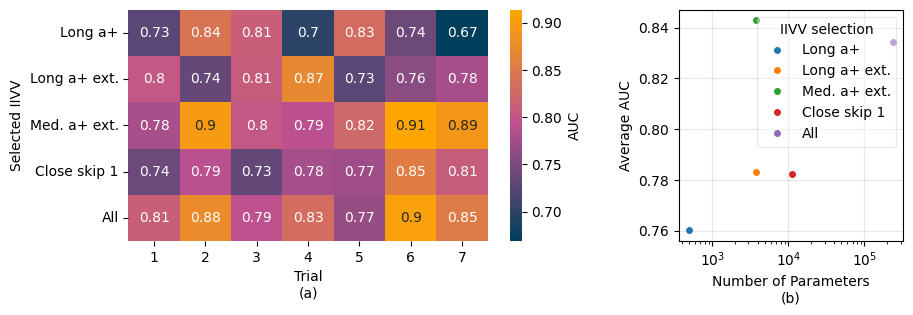

In [30]:
df_results = pd.DataFrame(results)
df_pivot = df_results.pivot(index="Mask", columns="Trial", values="AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Mask", "avg_AUC"]
df_params = pd.DataFrame(numXparams)
df_plot = pd.merge(df_params, df_results_avg, on="Mask")

fig = plt.figure(figsize=(10, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.3)

# left plot
ax0 = fig.add_subplot(gs[0])
order = [
    "Long a+",
    "Long a+ ext.",
    "Med. a+ ext.",
    "Close skip 1",
    "All",
]  # defined order
df_pivot = df_pivot.reindex(order)  # apply pre-defined order
sns.heatmap(df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "AUC"}, ax=ax0)
ax0.set_ylabel("Selected IIVV")
ax0.set_xlabel("Trial\n(a)")
# ax0.set_title("Average AUC Heatmap")

# right plot
ax1 = fig.add_subplot(gs[1])
for idx, row in df_plot.iterrows():
    ax1.plot(
        row["n_params"],
        row["avg_AUC"],
        ".",
        label=row["Mask"],
        markersize=8,
    )
ax1.set_xlabel("Number of Parameters\n(b)")
ax1.set_ylabel("Average AUC")
ax1.grid(alpha=0.3)
ax1.set_xscale("log")
# ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

ax1.legend(title="IIVV selection", framealpha=0.4)
plt.savefig("results/IIVV_sel_perf.pdf", bbox_inches="tight")
plt.show()

In [22]:
df_plot

,Mask,n_params,avg_AUC
0,Long a+,496,0.760132
1,Long a+ ext.,3720,0.783096
2,Med. a+ ext.,3720,0.842800
3,Close skip 1,11160,0.782502
4,All,239568,0.834128
